# Effective mass of every GEVP basis of 1 to 6 operators, forward q = 0

One figure per (number of operators, pz), all bases of that number overlaid in one panel. GEVP as section 1 of `gevp_3pt_ratio_subsets.ipynb`.

In [1]:
#======== settings ========
#Effective mass of every GEVP basis made of 1 to 6 of the 6 operators, forward q = 0. Only the packed 2pt is read; nothing is saved unless plot_dir is set.
#  input: the packed final Delta 2pt with the most cfgs (forward q = 0: the C3input file is also C2pf and C2pi), 6 operators = 2 smearings x 3 gammas:
#         B = boosted [4.5, 2.25, 0.8], U = [1.5, 1.5, 0];  G5, G5G4, G3G5.  Every subset of them is a GEVP basis: 6 of 1 operator, 15 of 2, 20 of 3, 15 of 4, 6 of 5, 1 of 6.
#  GEVP as section 1 of gevp_3pt_ratio_subsets.ipynb: per half (forward, backward), C(t) = c_sign x hermitian part of the t_src-averaged matrix of the subset;
#         C(t_ref) v = lambda C(t0) v on its cfg mean (Cholesky of C(t0)); v0 = ground-state vector, normalized to v0^dag C(t0) v0 = 1;
#         reconstructed 2pt of every cfg = Re v0^dag C_cfg(t) v0. A subset of one operator gives that operator's diagonal 2pt.
#  m_eff(t) = ln C(t)/C(t+1) on the delete-one jackknife replicates over cfgs, of the forward, backward or fb = (forward + backward)/2 reconstructed 2pt.
#  plots: one figure per (number of operators, pz), one panel per subset, all panels on the same axes.
import os
import glob
import itertools
import h5py
import numpy as np
import matplotlib.pyplot as plt

here = "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta"
hadron = "pion"                                 # "pion" or "proton" (the proton reads the _projected file)
DIRECTION = "fb"                                # "forward", "backward" or "fb"
n_op_list = [1, 2, 3, 4, 5, 6]                  # numbers of operators in a basis: one set of figures each
pz_plot = [0, 1, 2, 3, 4, 5, 6]                 # one figure per pz
t0, t_ref = 1, 3                                # GEVP C(t_ref) v = lambda C(t0) v, as in gevp_3pt_ratio_subsets.ipynb
t_plot = np.arange(1, 19)                       # t of the m_eff points (tsep 0..19 gives m_eff up to t = 18); t = 0 needs tsep 0, and the backward proton tsep 0 is not usable
m_had = {"pion": 0.141, "proton": 0.51}[hadron] # for the continuum dispersion line and the y range
y_range = {"pion": (-0.1, 0.4), "proton": (-0.2, 0.6)}[hadron]   # y axis of every panel: E_disp + y_range
plot_dir = None                                 # a folder to also save every figure as png; None: only show
Ls, Lt = 32, 96
c_sign = {"pion": -1, "proton": +1}[hadron]     # the pion comes out negative (the fermion-loop sign is not in the code), the projected proton positive

op_all = [(s, g) for s in range(2) for g in range(3)]      # (smear, gamma), operator a = 3 * smear + gamma
smear_short = ["B", "U"]                                    # smear 0 = B = [4.5, 2.25, 0.8], 1 = U = [1.5, 1.5, 0]

In [2]:
#======== GEVP of every subset and its effective mass ========
def ncfg_of(name):
    return int(name.split("_ncfg")[1].split("_")[0].split(".")[0])


def text(values):
    return [v.decode() if isinstance(v, bytes) else str(v) for v in values]


def jk(data):
    #mean and jackknife error over axis 0 of delete-one replicates
    n = data.shape[0]
    mean = np.mean(data, axis=0)
    return mean, np.sqrt((n - 1.0) / n * np.sum((data - mean) ** 2, axis=0))


def ground_state_vector(C_mean):
    #C_mean (op, op, tsep): ground-state vector of C(t_ref) v = lambda C(t0) v, normalized to v^dag C(t0) v = 1
    L_inv = np.linalg.inv(np.linalg.cholesky(C_mean[:, :, t0]))
    w, u = np.linalg.eigh(L_inv @ C_mean[:, :, t_ref] @ L_inv.conj().T)
    return (L_inv.conj().T @ u)[:, np.argmax(w)]


def subset_label(sub):
    #e.g. "{B G5, U G5G4}"
    return "{" + ", ".join(f"{smear_short[op_all[a][0]]} {gamma_list[op_all[a][1]]}" for a in sub) + "}"


#---- the packed forward q = 0 2pt with the most cfgs: the 6x6 operator matrix per half, mean over t_src
found = glob.glob(f"{here}/2pt_*_GEVP_forward_q0_0_0_C3input_*_{hadron}{'_projected' if hadron == 'proton' else ''}.h5")
assert found, f"no packed forward {hadron} 2pt in {here}"
pack_file = max(found, key=ncfg_of)
C = {}
with h5py.File(pack_file, "r") as f:
    cfg_list = f["cfg_list"][:]
    pz_list = f["pf_list"][:, 2].tolist()
    gamma_list = text(f.attrs["gamma_list"])
    for half in ["forward", "backward"]:
        x = f[f"pt2_{half}"][:].mean(axis=5)                         # (cfg, smear_snk, smear_src, g_snk, g_src, pz, tsep), mean over t_src
        n_cfg, n_pz, tsep_max = x.shape[0], x.shape[5], x.shape[6]
        assert x.shape[1] * x.shape[3] == len(op_all), "the smearings x gammas are not the 6 operators of op_all"
        x = x.transpose(0, 1, 3, 2, 4, 5, 6).reshape(n_cfg, len(op_all), len(op_all), n_pz, tsep_max)     # (cfg, op_snk, op_src, pz, tsep), op a = 3 * smear + gamma
        C[half] = c_sign * 0.5 * (x + np.conj(np.swapaxes(x, 1, 2)))                                     # hermitian part, sign c_sign
        assert (np.einsum("caapt->apt", C[half])[:, :, t0].mean(axis=1).real > 0).all(), f"{half}: diagonal of C(t0) is not positive, check c_sign"
        del x
print(f"{os.path.basename(pack_file)}: {n_cfg} cfgs, pz = {pz_list}, tsep 0..{tsep_max - 1}")

#---- every subset: v0 per (half, pz) from the cfg mean, reconstructed 2pt of every cfg, m_eff on the jackknife replicates
subsets = {n: list(itertools.combinations(range(len(op_all)), n)) for n in n_op_list}
meff_mean, meff_err = {}, {}                                         # subset -> (pz, t), t = 0 .. tsep_max - 2
for n in n_op_list:
    for sub in subsets[n]:
        idx = list(sub)
        C_rec = {}
        for half in ["forward", "backward"]:
            C_sub = C[half][:, idx][:, :, idx]                       # (cfg, op, op, pz, tsep)
            C_rec[half] = np.zeros((n_cfg, n_pz, tsep_max))
            for ip in range(n_pz):
                v0 = ground_state_vector(C_sub[:, :, :, ip].mean(axis=0))
                C_rec[half][:, ip] = np.einsum("a,cabt,b->ct", v0.conj(), C_sub[:, :, :, ip], v0).real
        C2 = 0.5 * (C_rec["forward"] + C_rec["backward"]) if DIRECTION == "fb" else C_rec[DIRECTION]     # (cfg, pz, tsep)
        C2_jk = (C2.sum(axis=0) - C2) / (n_cfg - 1)
        with np.errstate(invalid="ignore", divide="ignore"):
            meff_mean[sub], meff_err[sub] = jk(np.log(C2_jk[:, :, :-1] / C2_jk[:, :, 1:]))
print(f"{sum(len(subsets[n]) for n in n_op_list)} subsets of " + ", ".join(f"{smear_short[s]} {gamma_list[g]}" for s, g in op_all) + f";  t0 = {t0}, t_ref = {t_ref}, {DIRECTION}")

2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_smear_GEVP_forward_q0_0_0_C3input_fb_tsep20_3072src_ncfg183_pion.h5: 183 cfgs, pz = [0, 1, 2, 3, 4, 5, 6], tsep 0..19
63 subsets of B G5, B G5G4, B G3G5, U G5, U G5G4, U G3G5;  t0 = 1, t_ref = 3, fb


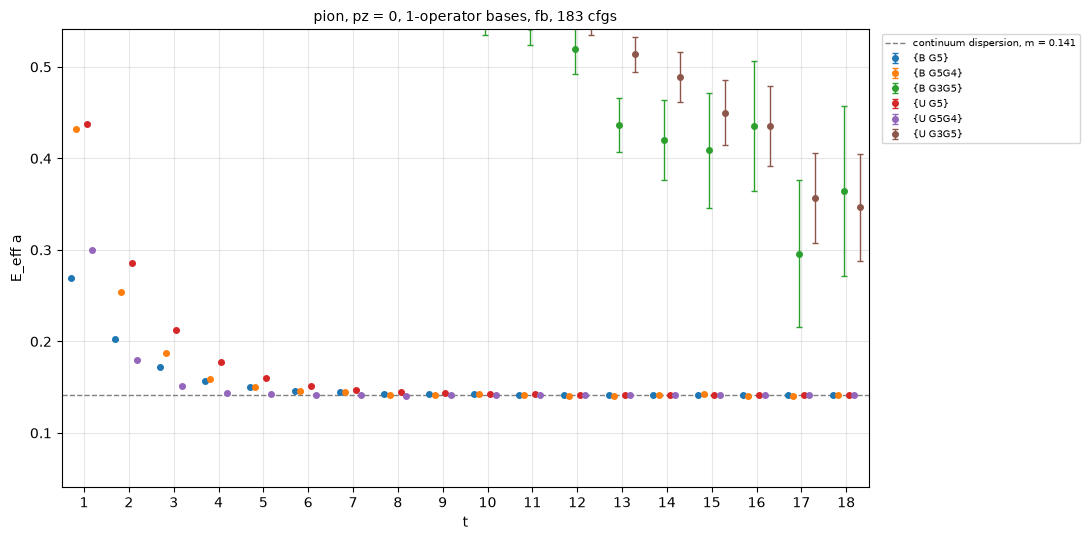

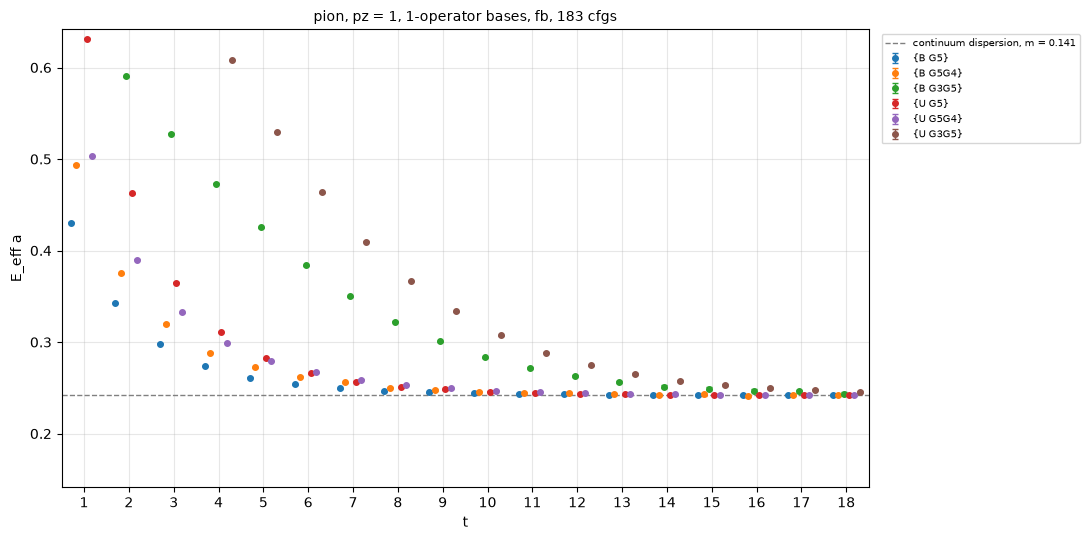

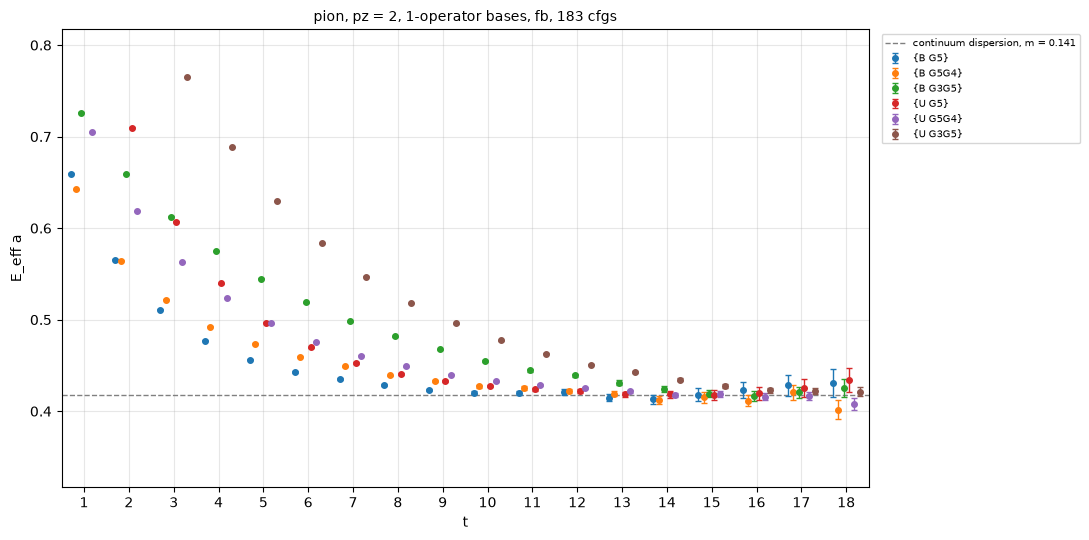

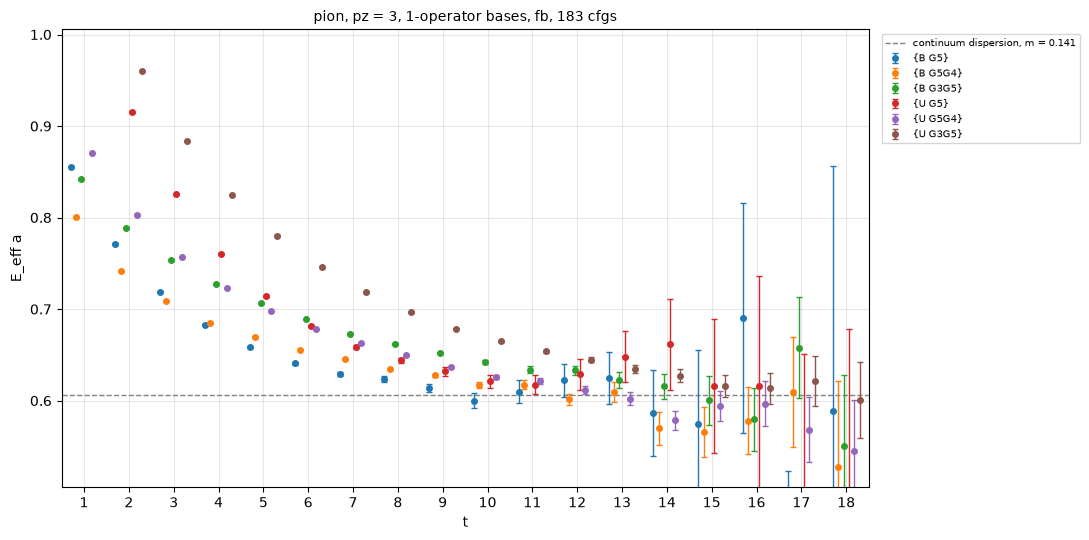

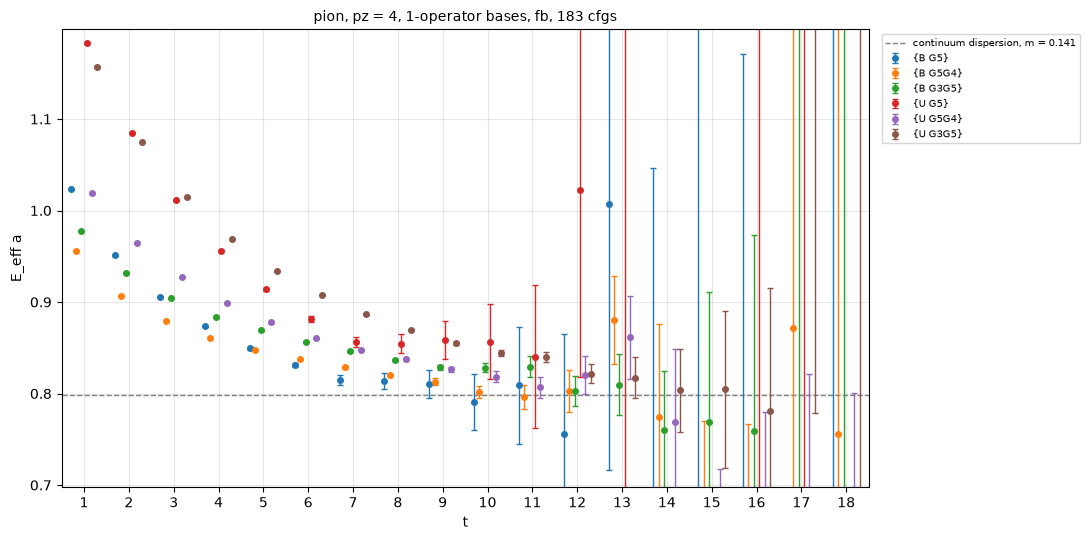

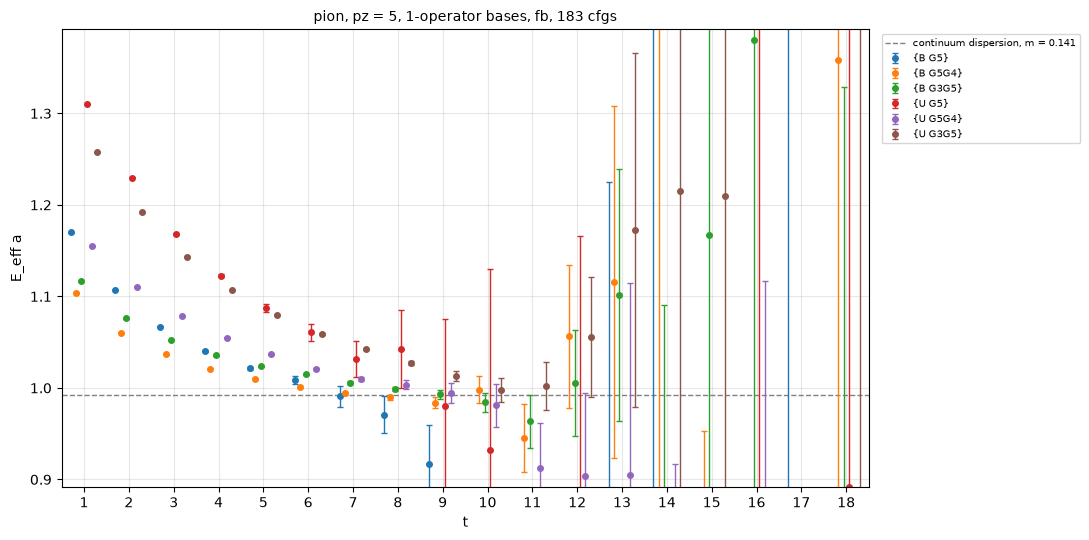

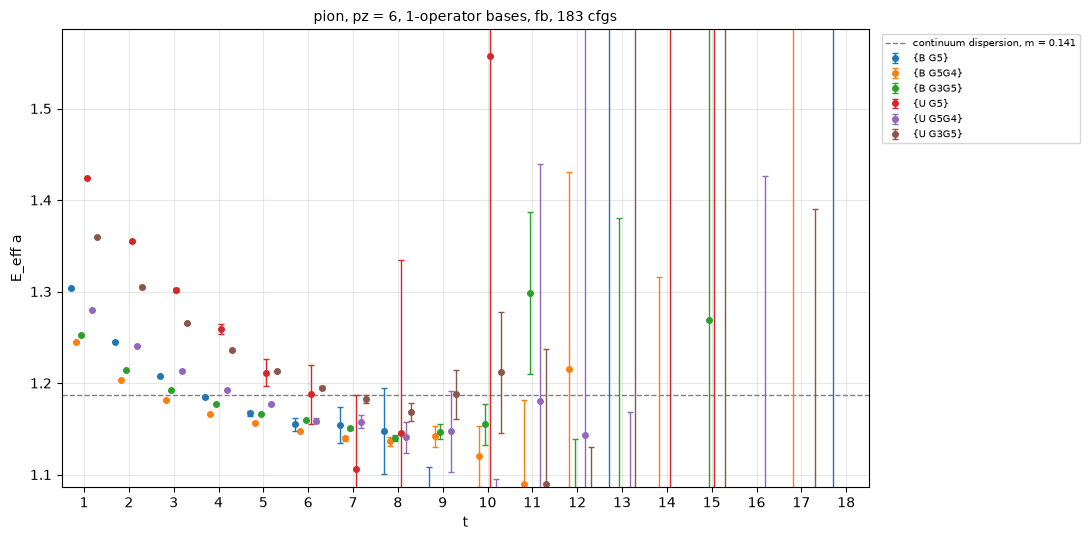

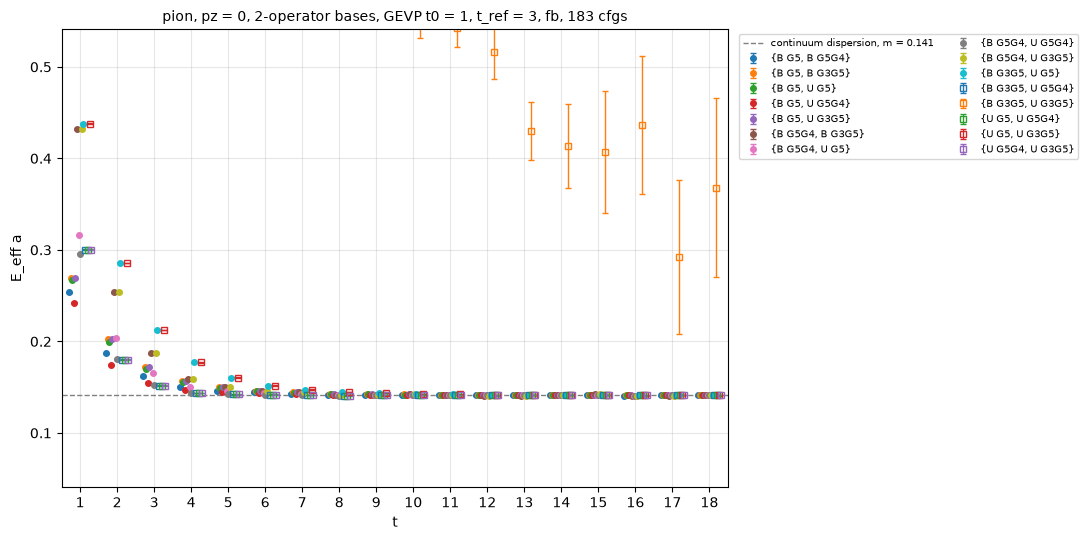

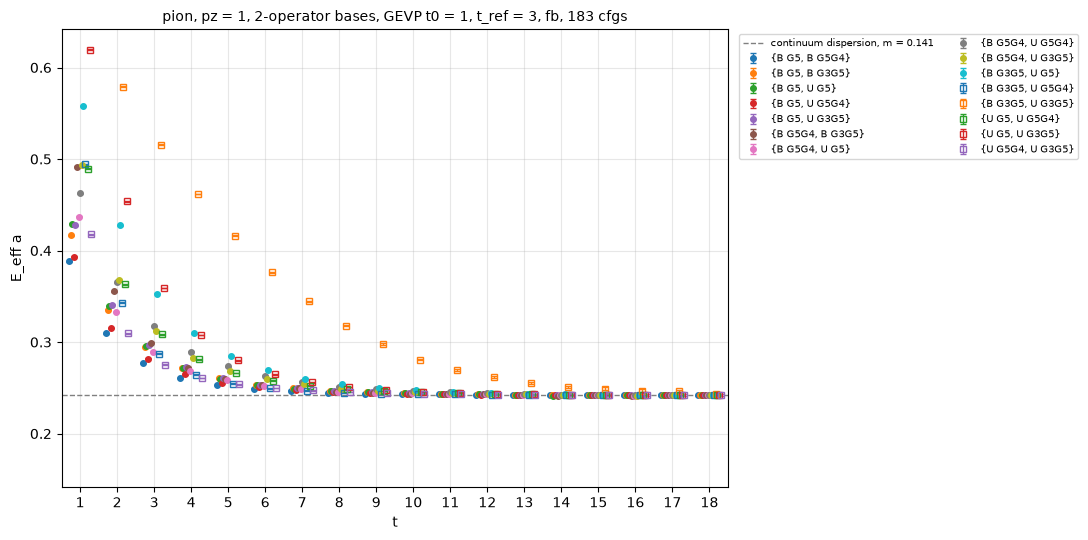

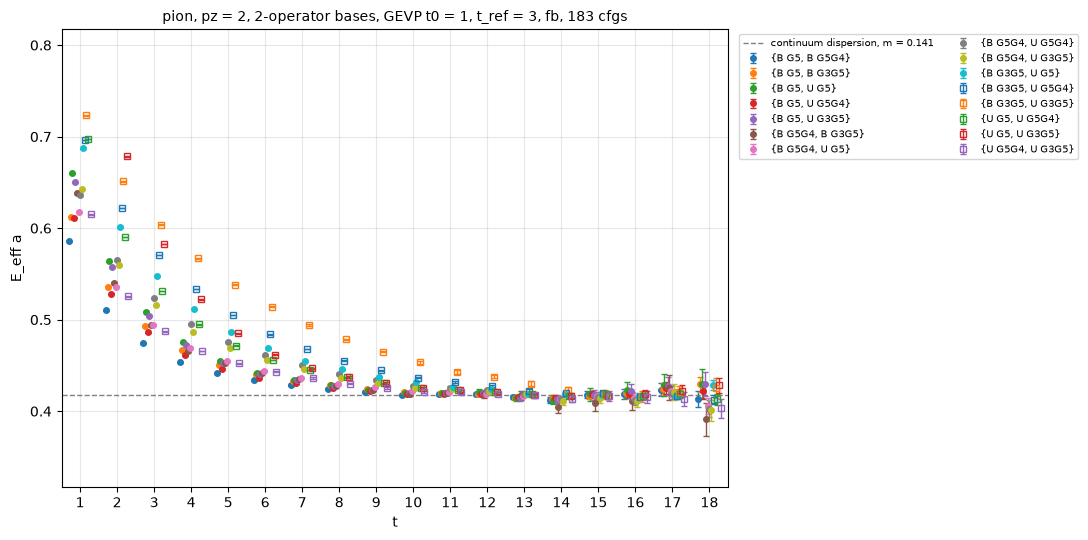

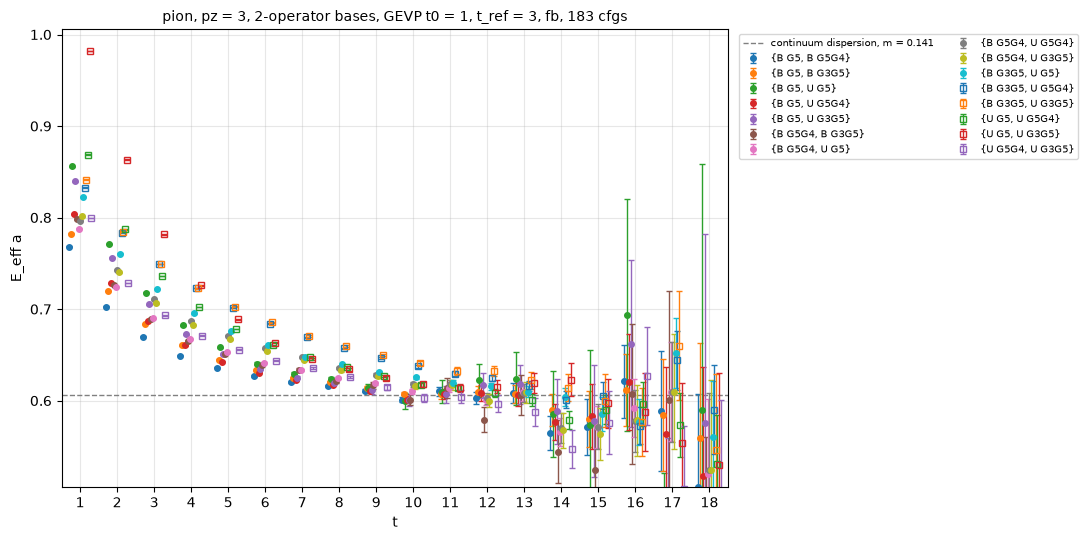

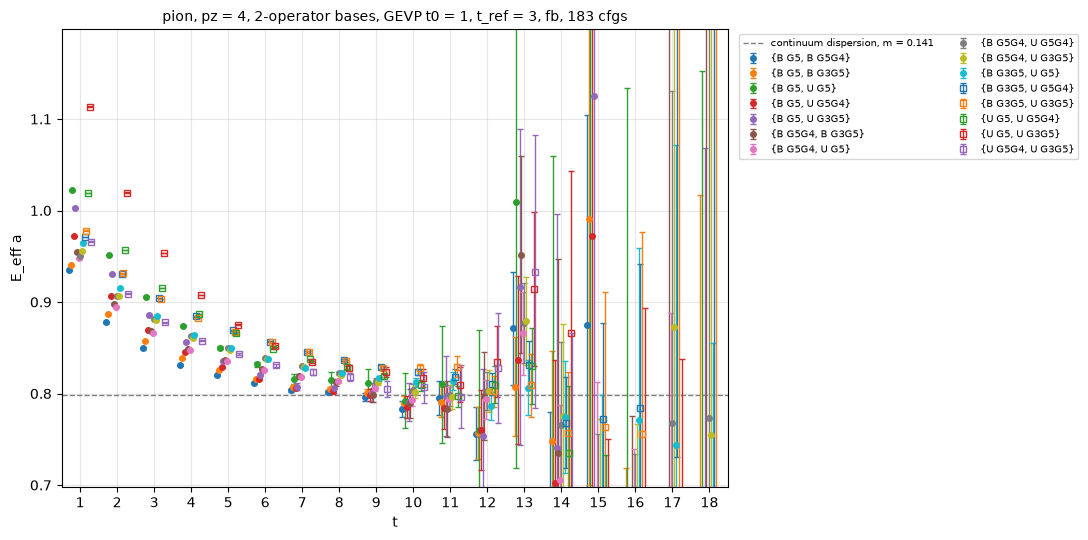

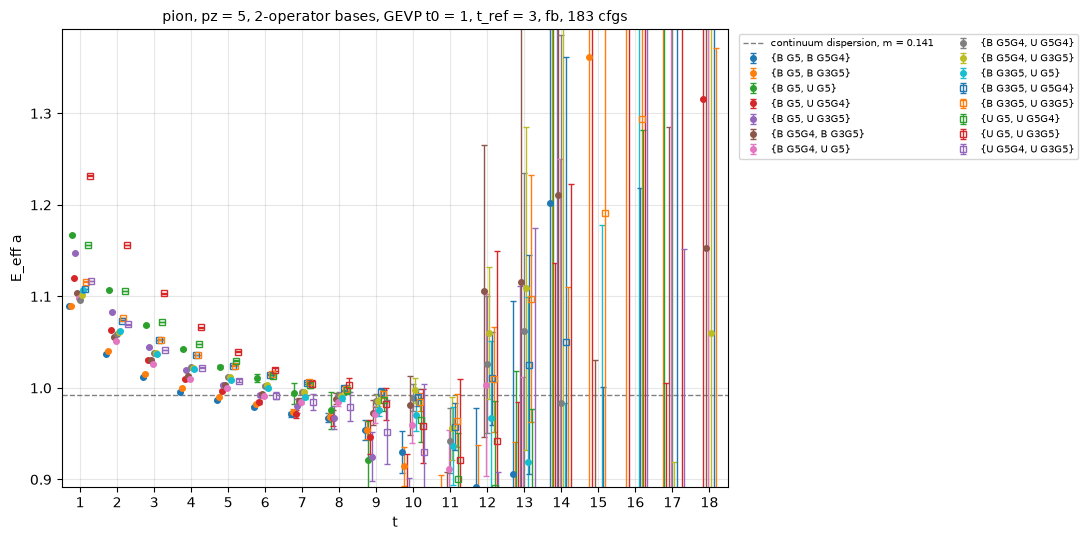

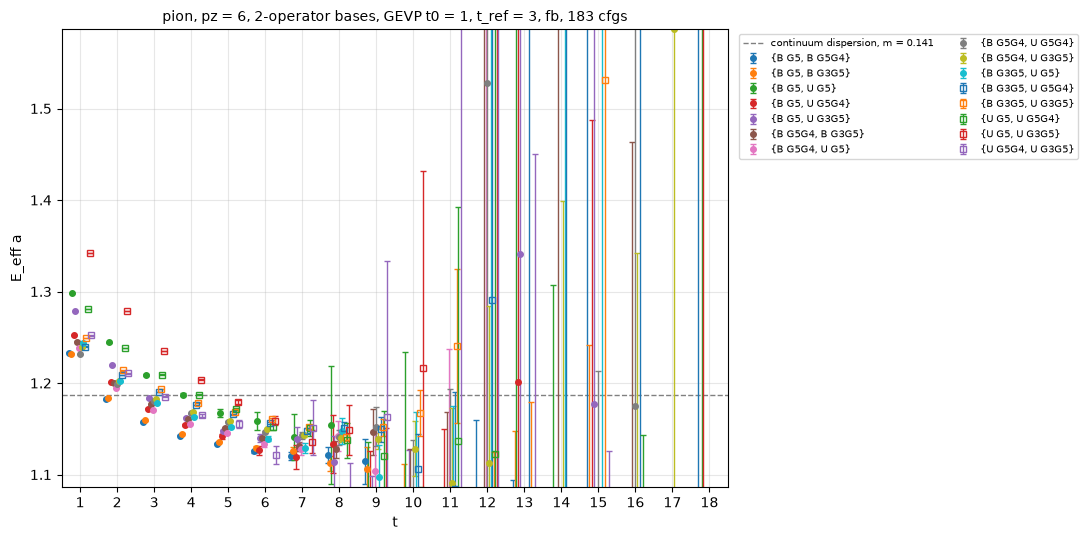

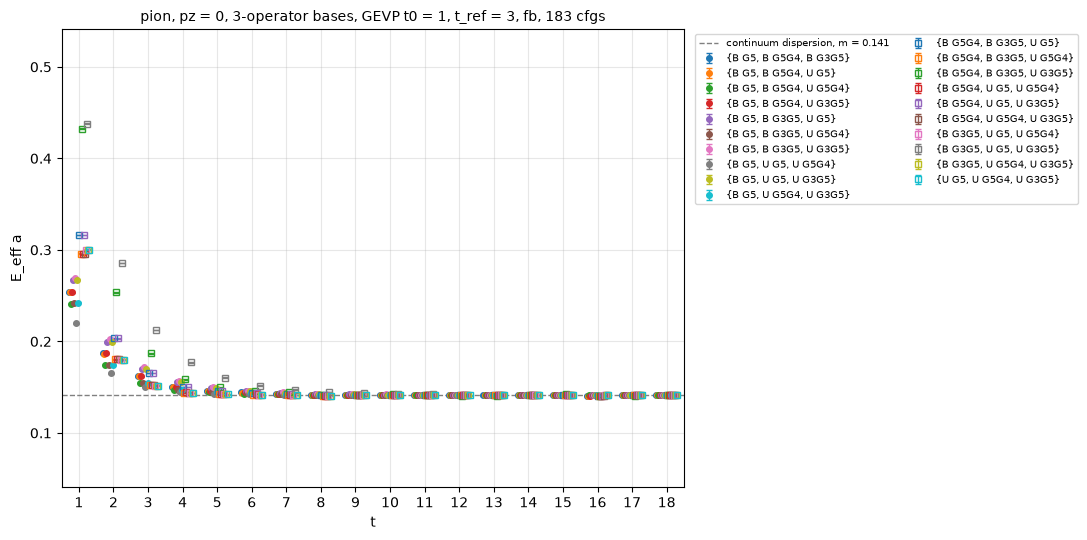

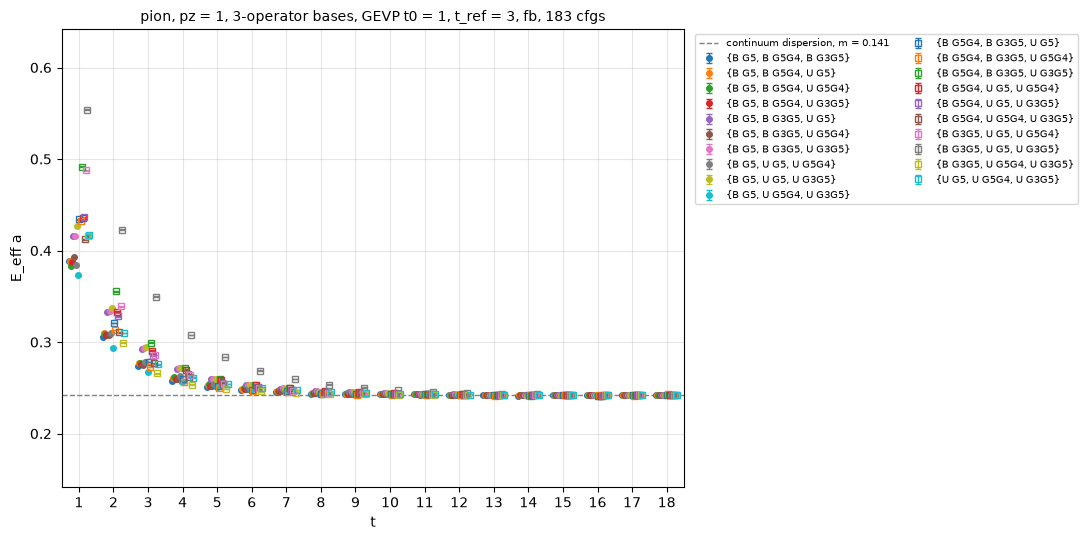

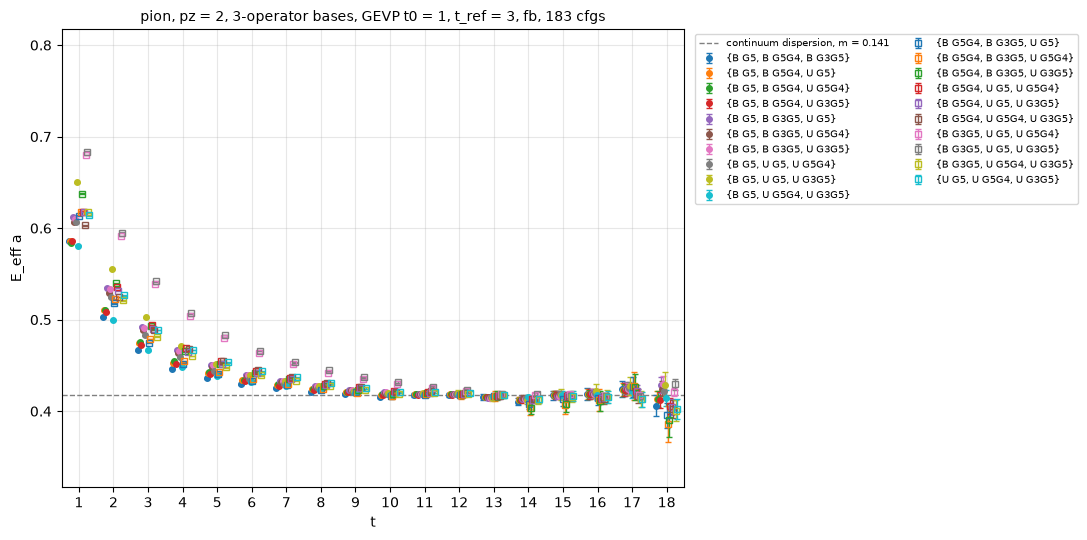

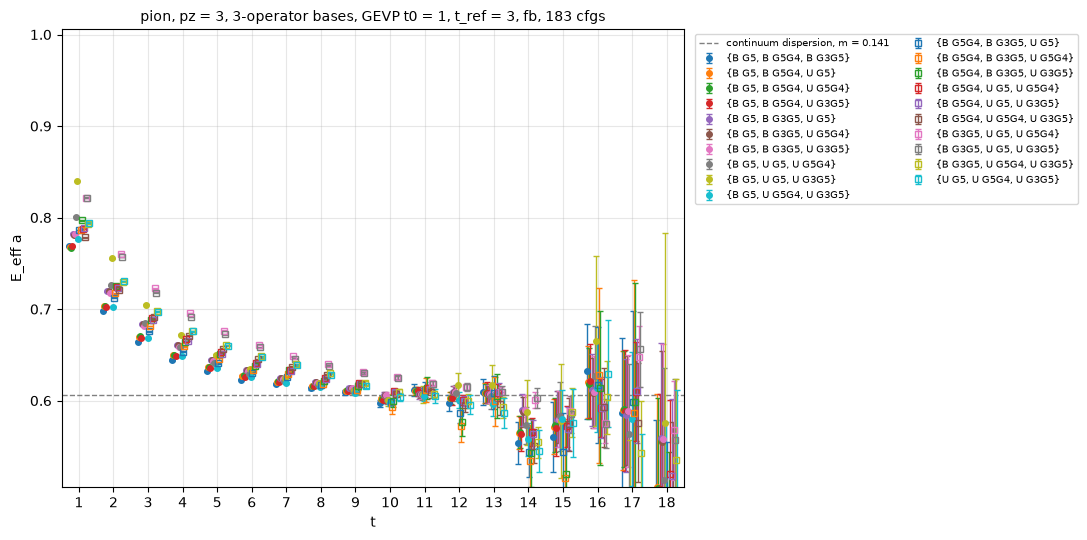

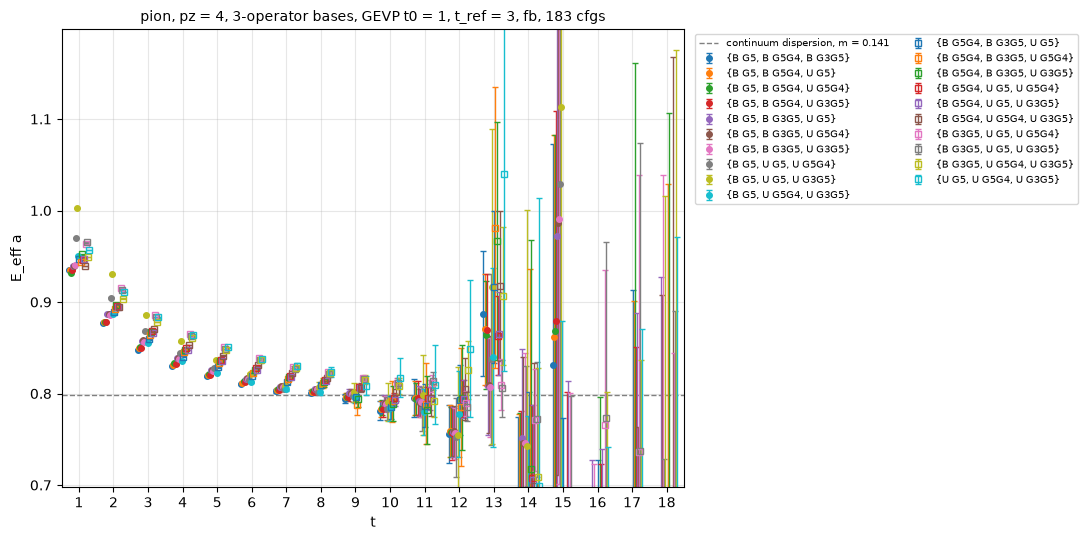

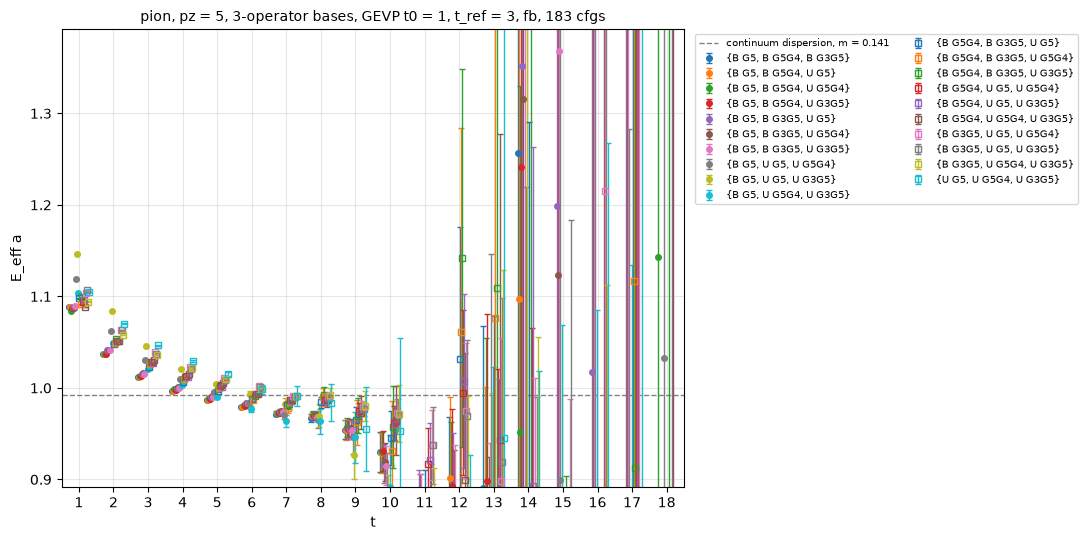

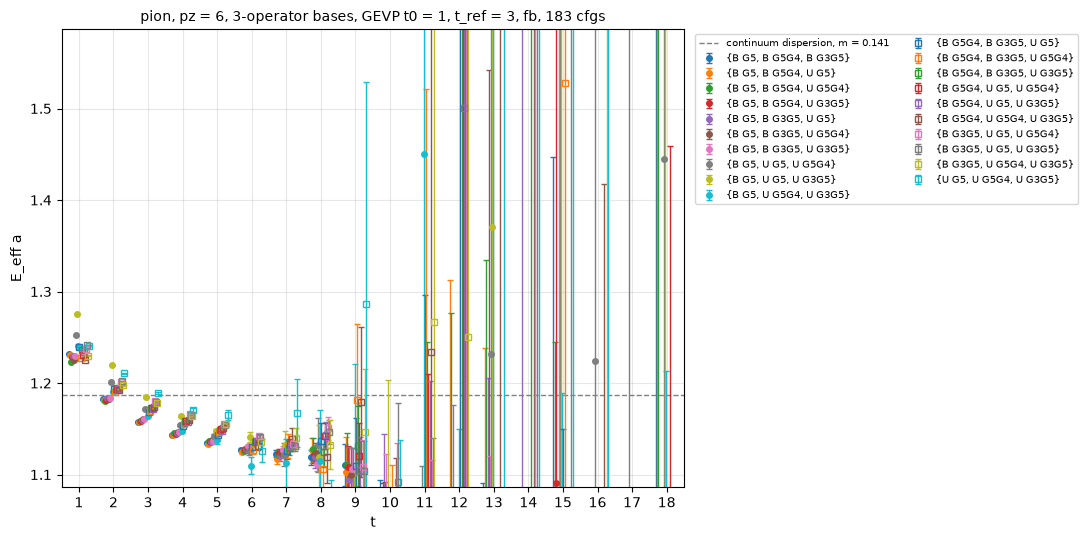

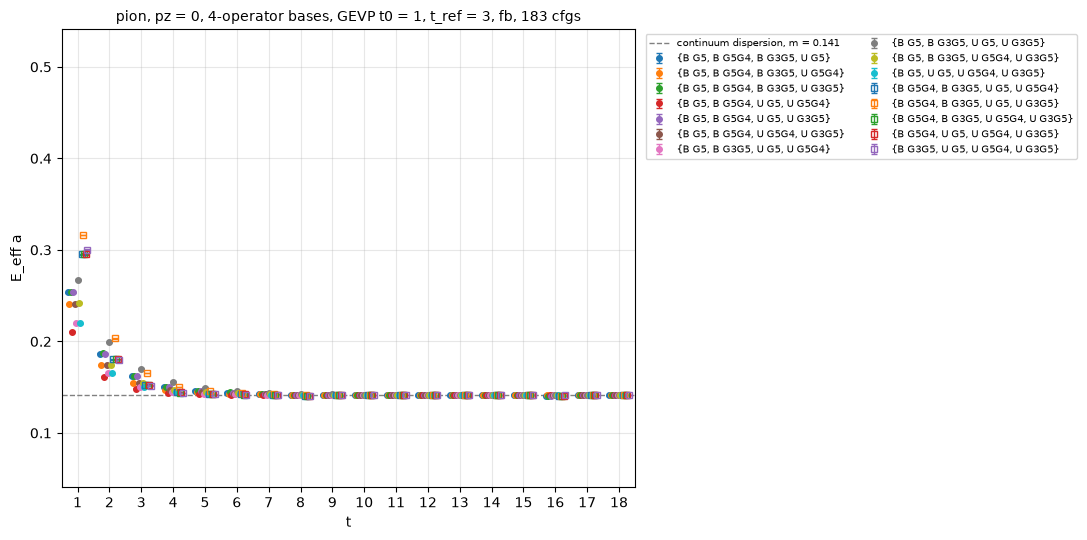

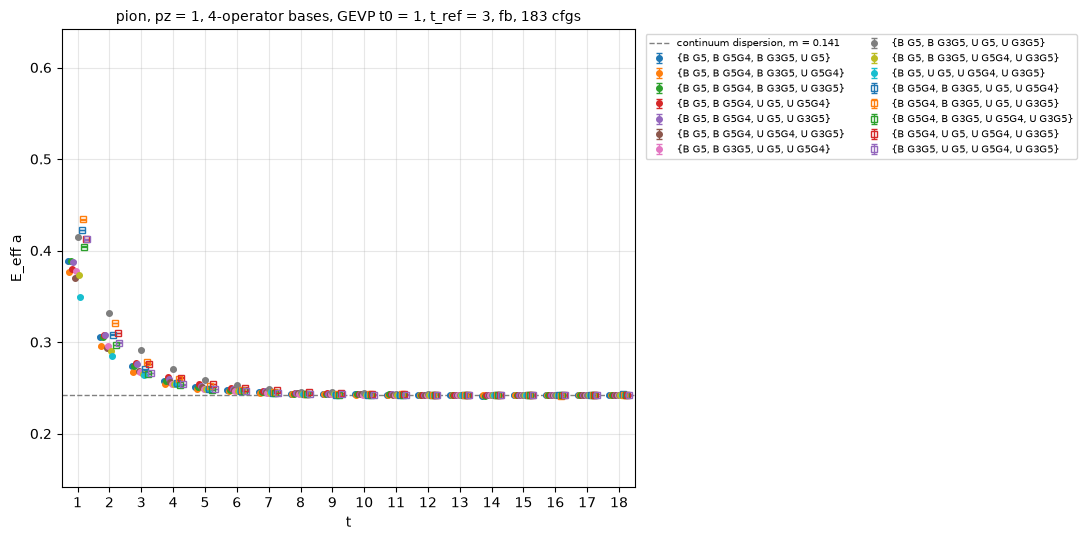

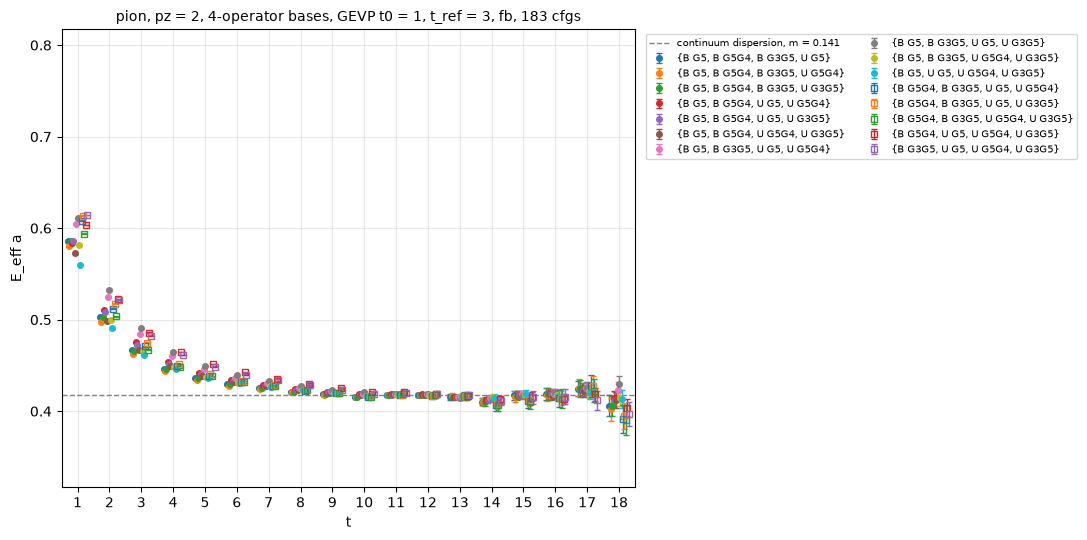

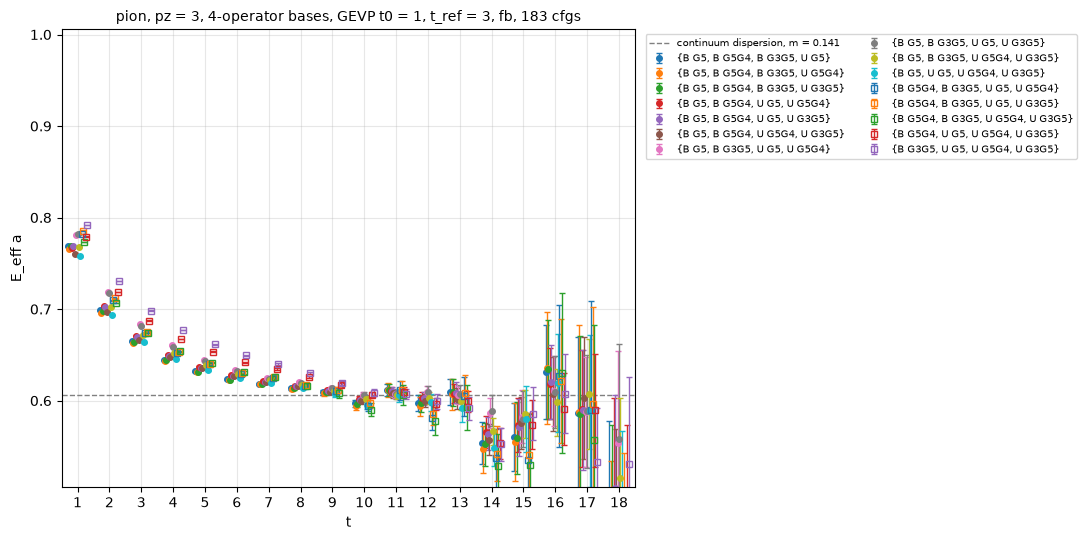

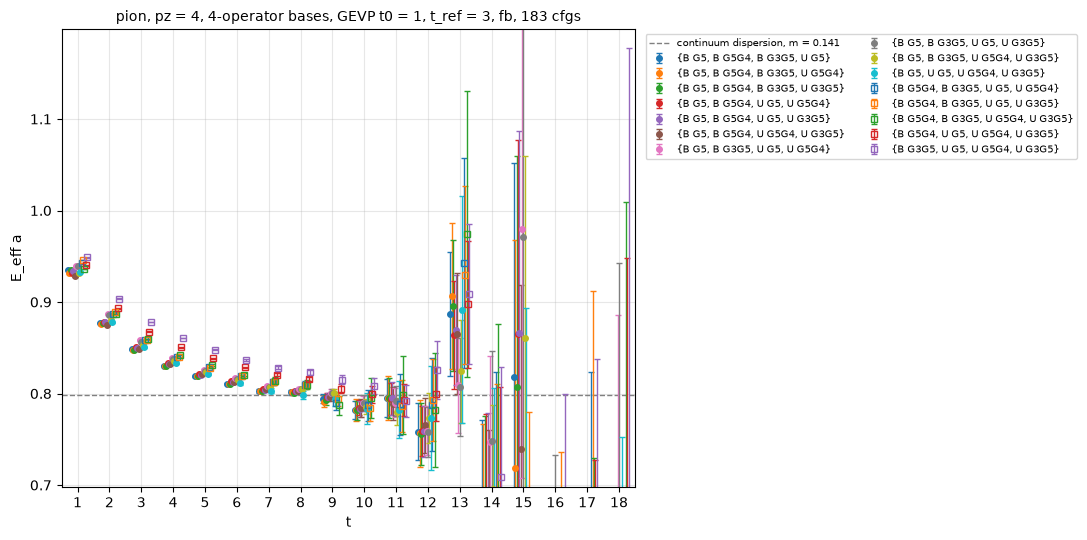

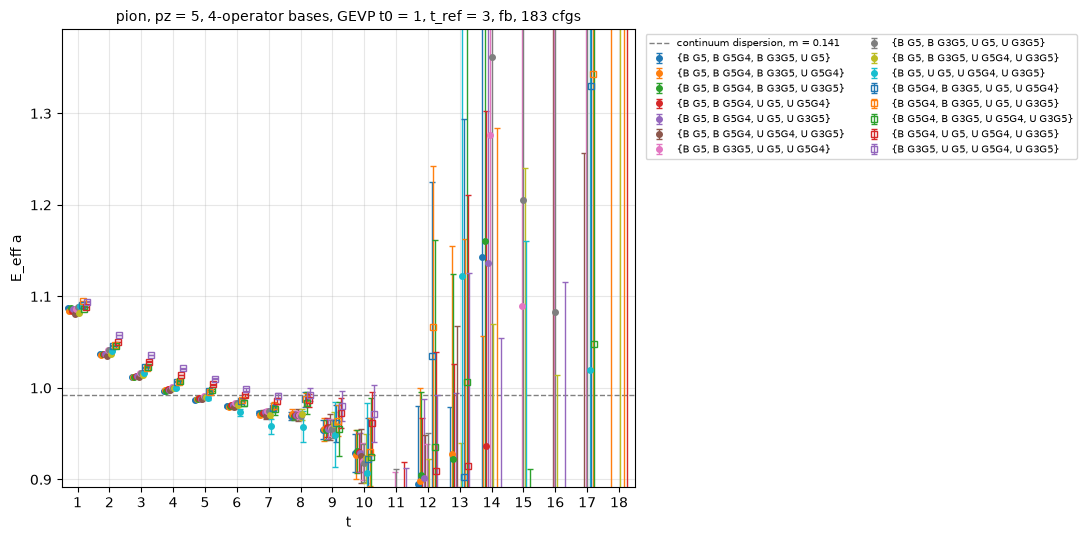

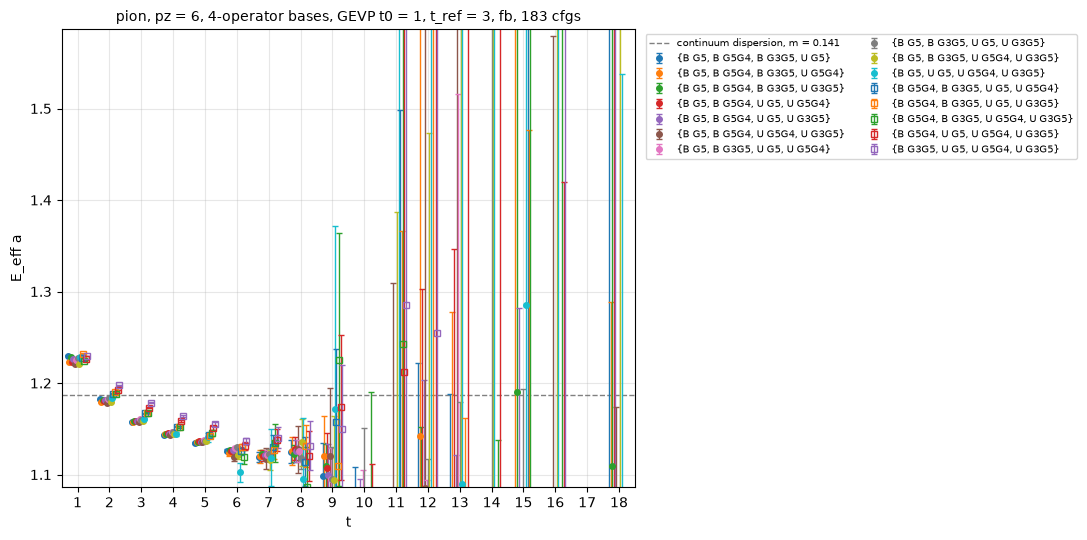

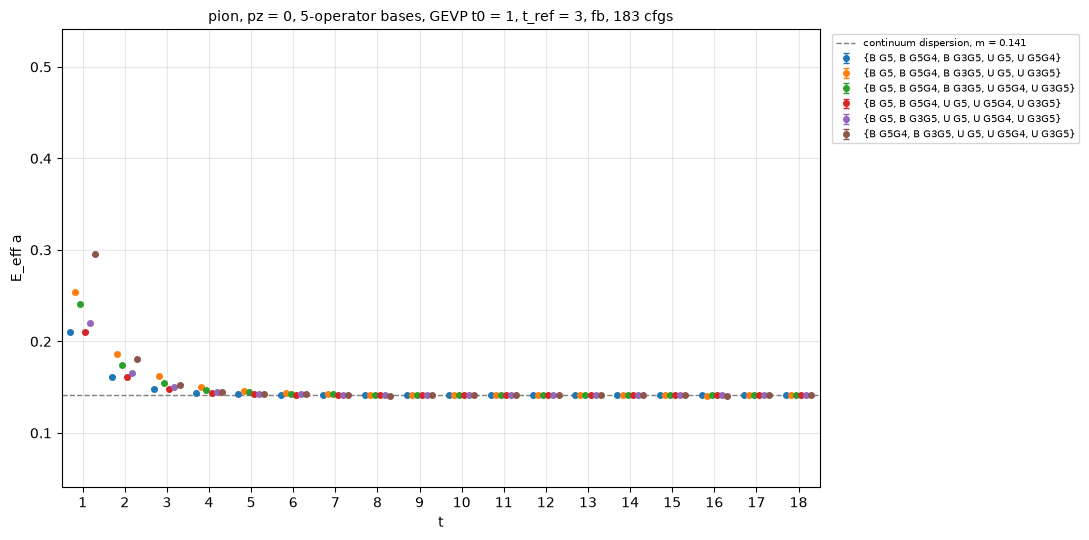

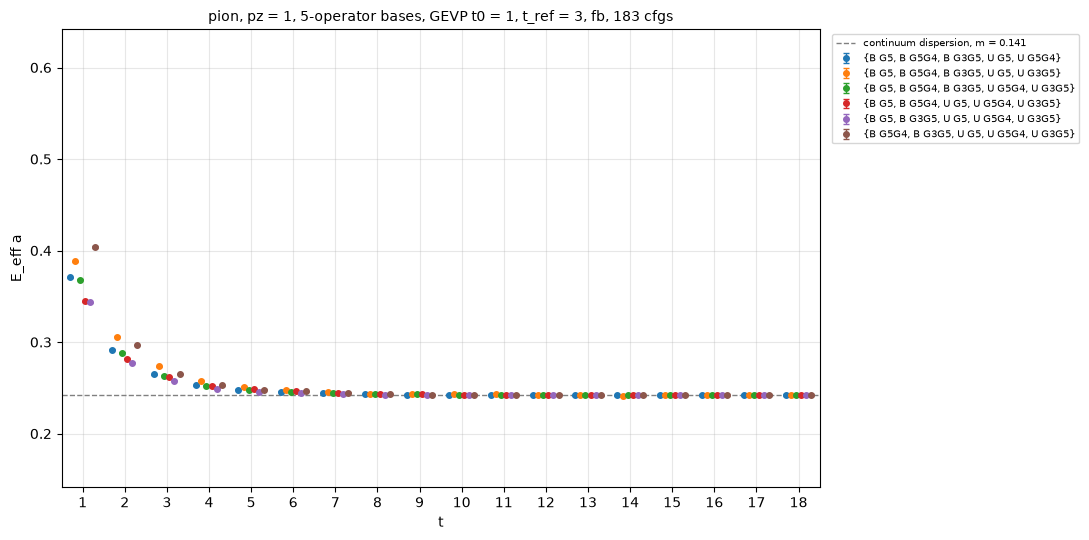

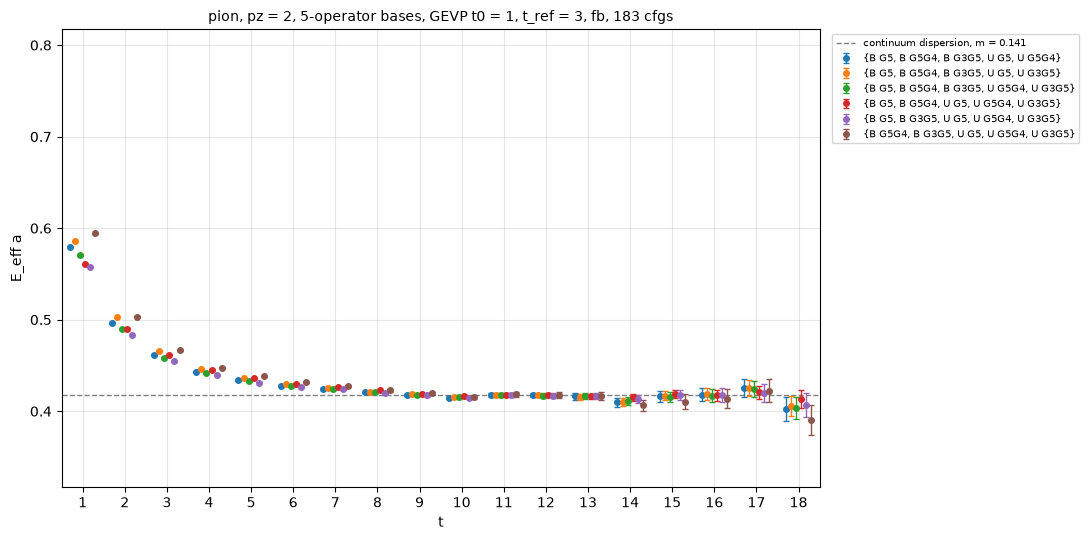

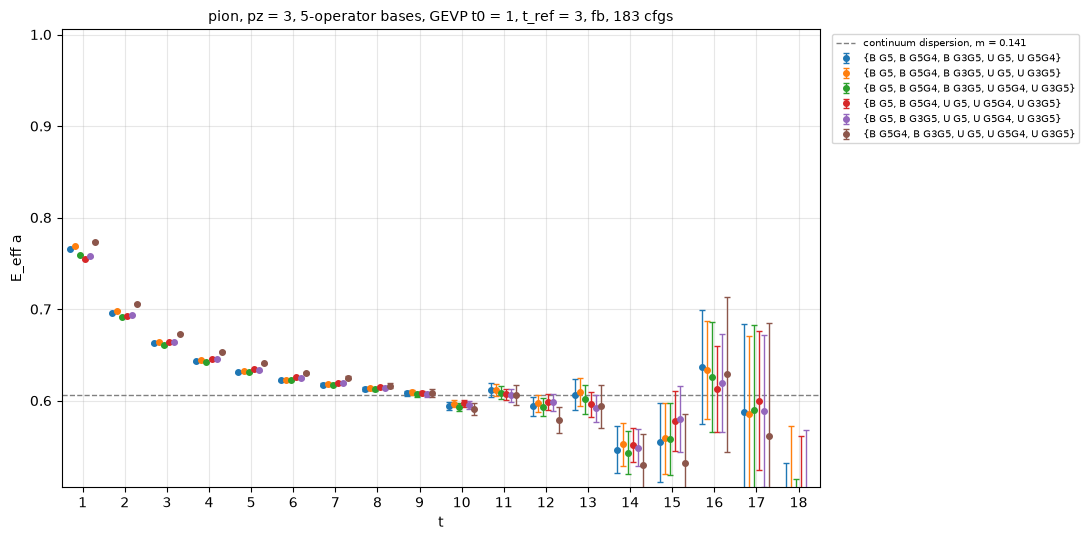

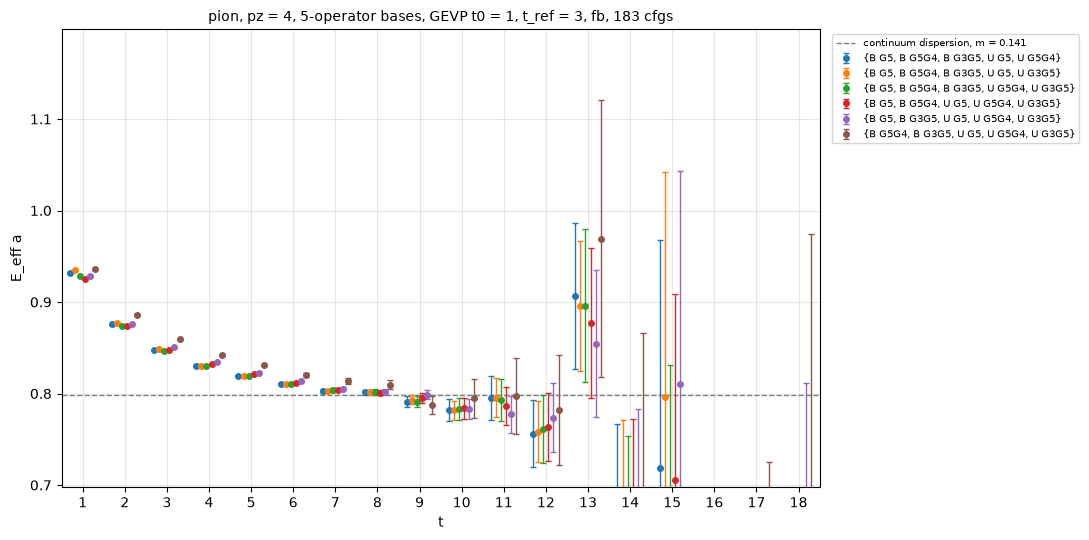

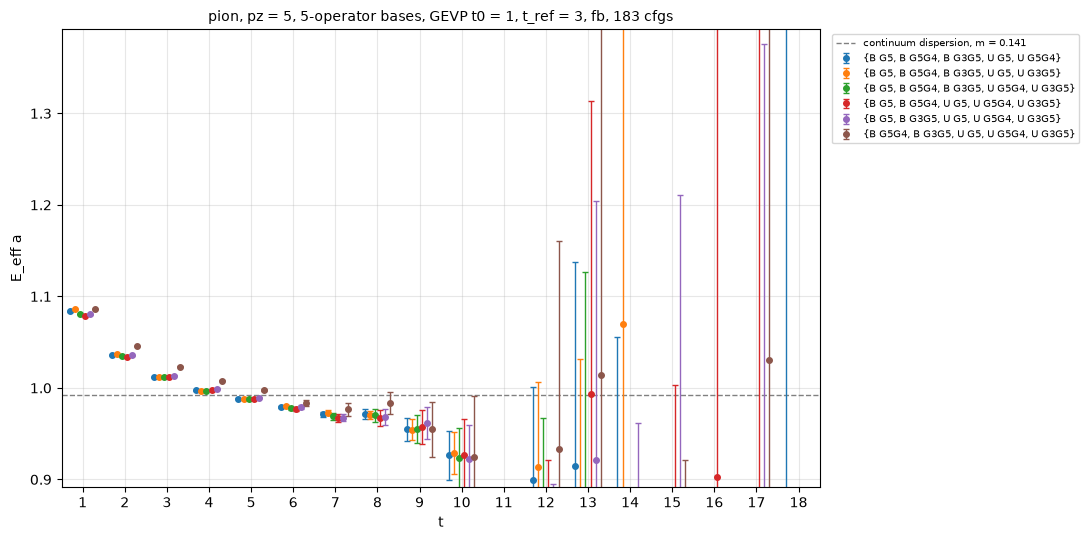

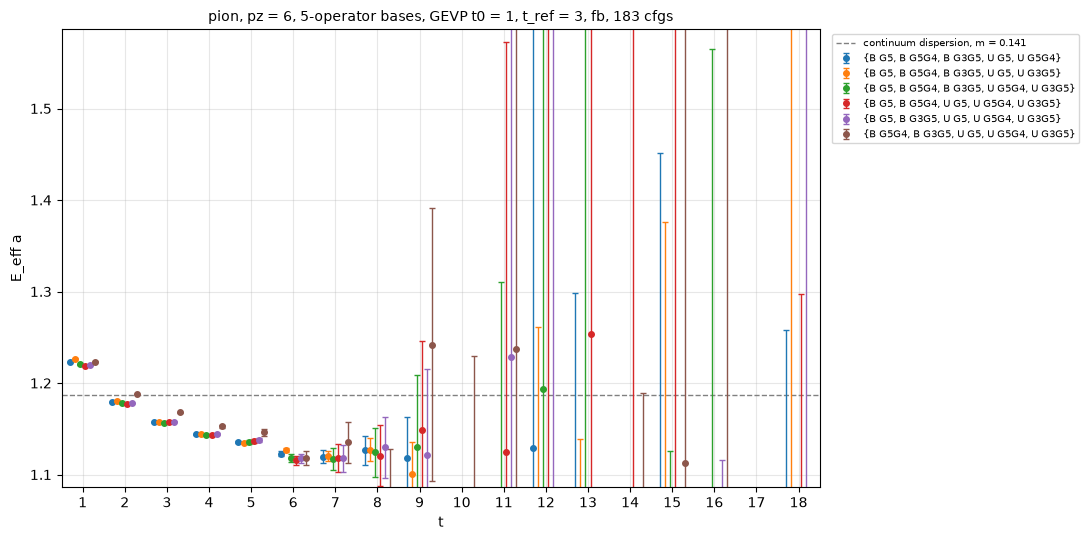

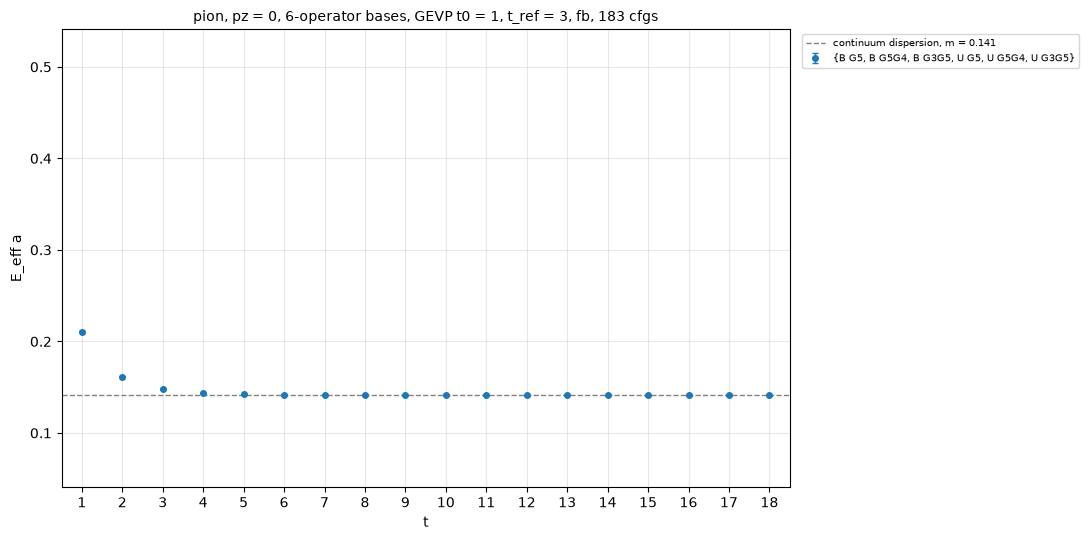

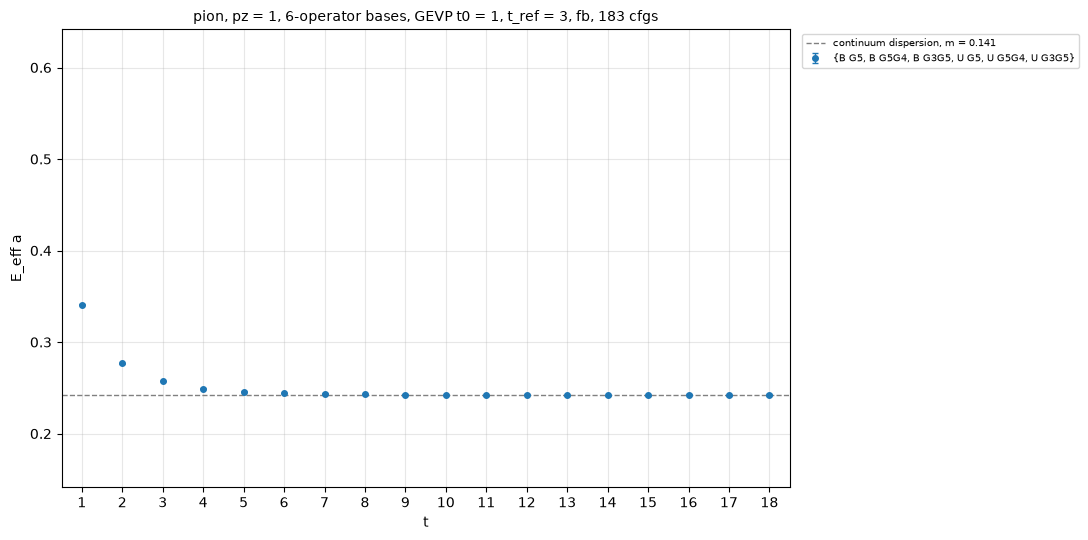

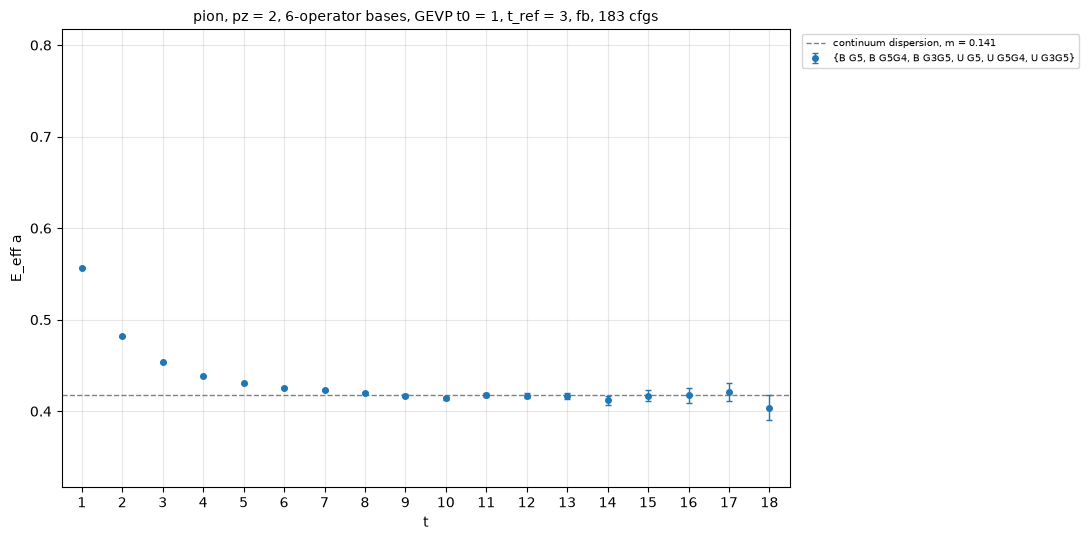

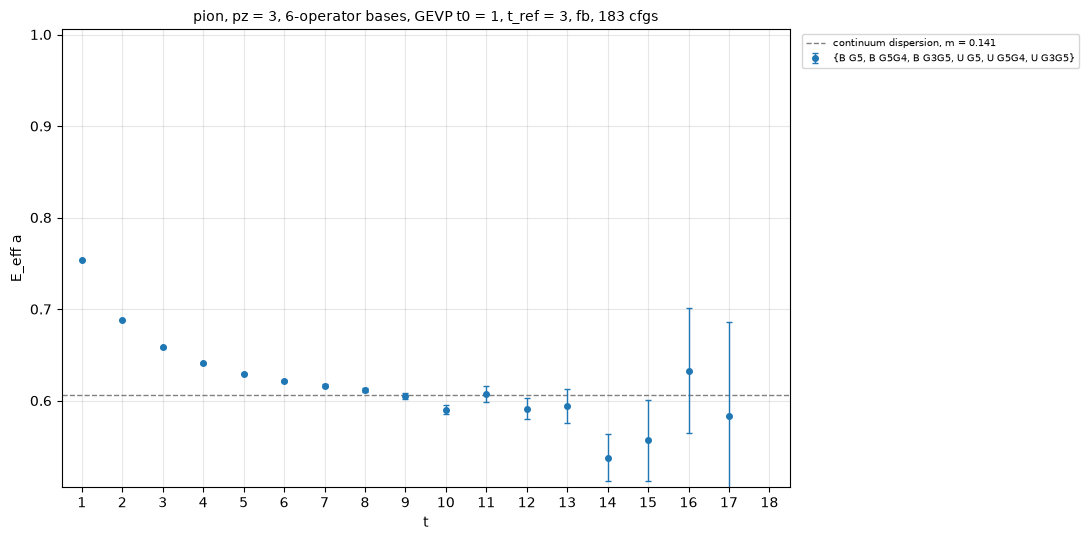

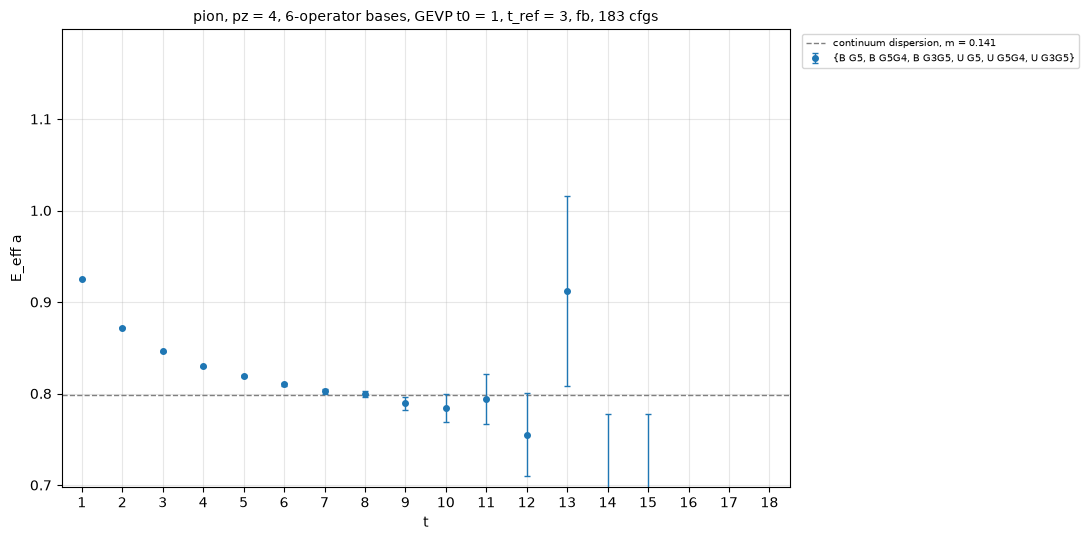

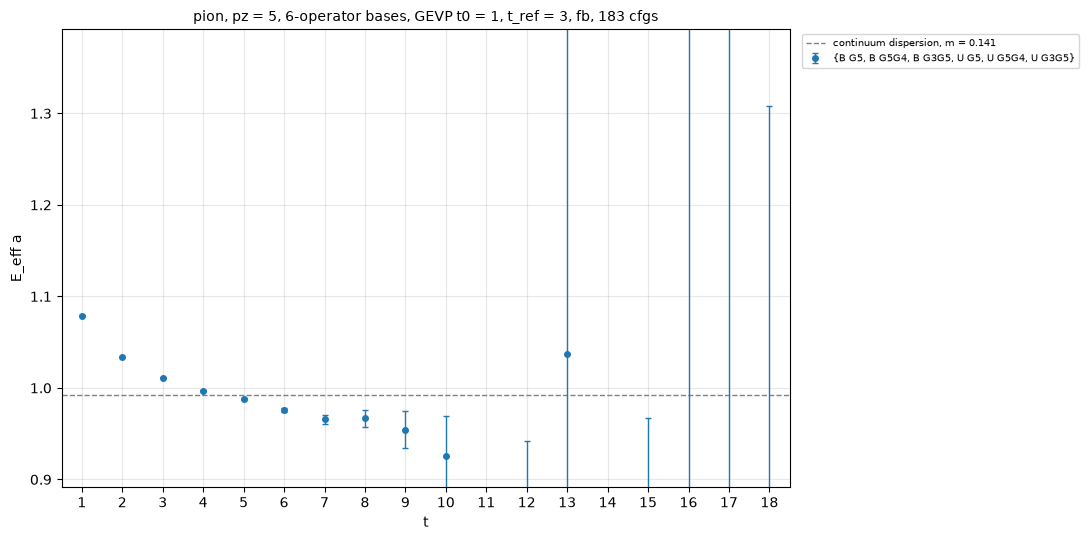

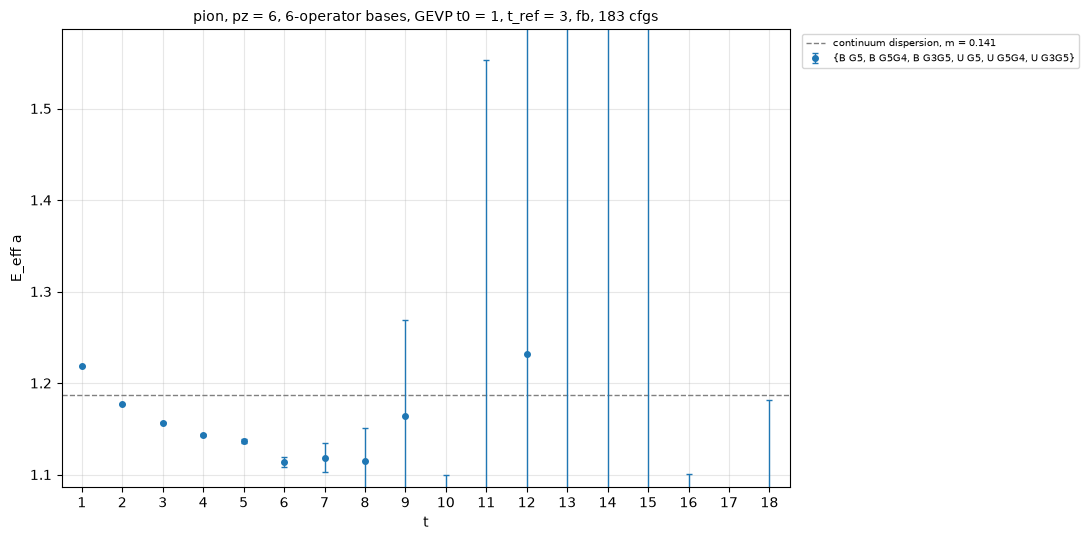

In [3]:
#======== plots: one figure per (number of operators, pz), all subsets of that number overlaid in one panel ========
#subset i: color C{i % 10}, marker by i // 10 (filled for i < 10, hollow after), shifted in t by up to +-0.3 so the error bars do not overlap
MARKERS = ["o", "s", "^", "D"]
if plot_dir:
    os.makedirs(plot_dir, exist_ok=True)
for n in n_op_list:
    subs = subsets[n]
    shift = np.linspace(-0.3, 0.3, len(subs)) if len(subs) > 1 else [0.0]
    for pz in pz_plot:
        ip = pz_list.index(pz)
        E_disp = np.sqrt(m_had ** 2 + (2 * np.pi * pz / Ls) ** 2)
        fig, ax = plt.subplots(figsize=(11, 5.5))
        ax.axhline(E_disp, color="gray", lw=1, ls="--", label=f"continuum dispersion, m = {m_had}")
        for i, sub in enumerate(subs):
            color = f"C{i % 10}"
            ax.errorbar(t_plot + shift[i], meff_mean[sub][ip, t_plot], meff_err[sub][ip, t_plot], fmt=MARKERS[i // 10], ms=4, capsize=2, lw=1,
                        color=color, mfc=color if i < 10 else "none", label=subset_label(sub))
        ax.set_ylim(E_disp + y_range[0], E_disp + y_range[1])
        ax.set_xlim(t_plot[0] - 0.5, t_plot[-1] + 0.5)
        ax.set_xticks(t_plot)
        ax.set_xlabel("t")
        ax.set_ylabel("E_eff a")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1), ncol=1 if len(subs) <= 10 else 2)
        title = f"{hadron}, pz = {pz}, {n}-operator bases" + (f", GEVP t0 = {t0}, t_ref = {t_ref}" if n > 1 else "")
        ax.set_title(f"{title}, {DIRECTION}, {n_cfg} cfgs", fontsize=10)
        fig.tight_layout()
        if plot_dir:
            fig.savefig(f"{plot_dir}/meff_{n}op_{hadron}_forward_pz{pz}_t0{t0}_tref{t_ref}_{DIRECTION}.png", dpi=120)
        plt.show()
        plt.close(fig)